# Two synthetic Heston samples

**MA52109 micro-project: NumPy simulation, reusable functions and Matplotlib.**

We draw two different parameter vectors and simulate one underlying-price and
variance history for each. These are **not option-price paths**. We use a one-year
grid, 1,000 steps and seed 42. All computations use NumPy; plots use Matplotlib.

Before running, install the package with `python -m pip install -e .` from the
project root and select that environment as this notebook's kernel. Run all
cells from top to bottom. Notebook tooling is optional; `demo/demo_heston.py`
also runs the demonstration without Jupyter.

### Questions
1. What are the shapes of a parameter batch and a batch of full histories?
2. How do price and variance change along each generated history?
3. How can we summarise, save and visualise these arrays without Pandas?


In [5]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from methodsheston_micro import (
    PARAM_NAMES,
    PARAM_RANGES,
    make_prior_spec,
    sample_parameters,
    make_euler_grid,
    simulate_heston_paths,
    HestonSample,
    save_sample,
    load_sample,
)
from heston_micro.visualisations import (
    plot_paths,
    plot_return_histograms,
    plot_price_variance,
    plot_drawdowns,
)

np.set_printoptions(precision=5, suppress=True)
print("NumPy:", np.__version__)


ModuleNotFoundError: No module named 'methodsheston_micro'

## 1. Prior specification and two parameter draws

Column order is `v_0, kappa, theta, xi, rho`. The first four parameters are
positive and use log coordinates; rho remains in its original coordinate.
For transformed bounds a and b, mu = (a+b)/2 and sigma = (b-a)/2. We sample a
normal truncated to [mu-sigma, mu+sigma], not an unrestricted normal and not a
uniform distribution. The sigma in this specification is the underlying
normal's scale, not the standard deviation after truncation.

`rng` is created once and reused. Each parameter row stays fixed over time.


In [ ]:
seed = 42
rng = np.random.default_rng(seed)
transformed_bounds, norm_params = make_prior_spec()
parameters = sample_parameters(n_samples=2, rng=rng)
print("Parameter order:", PARAM_NAMES)
print("Sampled parameters:\n", parameters)
print("Parameter shape:", parameters.shape)

for j, name in enumerate(PARAM_NAMES):
    lo, hi = PARAM_RANGES[name]
    assert np.all((parameters[:, j] >= lo) & (parameters[:, j] <= hi))


Parameter order: ['v_0', 'kappa', 'theta', 'xi', 'rho']
Sampled parameters:
 [[ 0.22456  3.78763  0.30689  1.3558  -0.01666]
 [ 0.1706   0.67114  0.03809  0.26615 -0.87285]]
Parameter shape: (2, 5)


## 2. Time grid and joint simulation

Euler-Maruyama uses Brownian increments sqrt(dt) Z. The price and variance
increments share one normal draw to obtain correlation rho. We evolve log-price
and raw variance together, using the old nonnegative variance in both updates.

Full truncation keeps the raw variance internally even if it becomes negative;
the returned effective variance is max(raw variance, 0). This prevents taking a
square root of a negative value, but does not remove discretisation bias.
Arrays have shape `(samples, times)` and include the initial state.


In [ ]:
maturities = np.array([0.25, 0.50, 1.00])
times, dt, maturity_indices = make_euler_grid(maturities, steps_per_year=1000)
prices, variances = simulate_heston_paths(
    parameters, times, rng, S_0=1.0, drift=0.0
)
sample = HestonSample(parameters, times, prices, variances, seed, 1.0, 0.0)

print("dt:", dt)
print("Selected maturity indices:", maturity_indices)
print("Prices:", prices.shape, "| variances:", variances.shape)
print("Prices at selected maturities:\n", prices[:, maturity_indices])
assert prices.shape == variances.shape == (2, 1001)
assert np.all(np.isfinite(prices)) and np.all(prices > 0)
assert np.all(variances >= 0)
np.testing.assert_array_equal(variances[:, 0], parameters[:, 0])


dt: 0.001
Selected maturity indices: [ 250  500 1000]
Prices: (2, 1001) | variances: (2, 1001)
Prices at selected maturities:
 [[0.88239 0.7284  0.94464]
 [0.88853 0.80394 0.83498]]


## 3. Line plots: underlying and effective variance

The two rows have different parameters AND different random shocks. These
figures illustrate histories; they do not isolate the causal effect of one
parameter. Dashed lines indicate theta, the long-run variance parameter, not
an assertion that a single path must quickly converge to it.


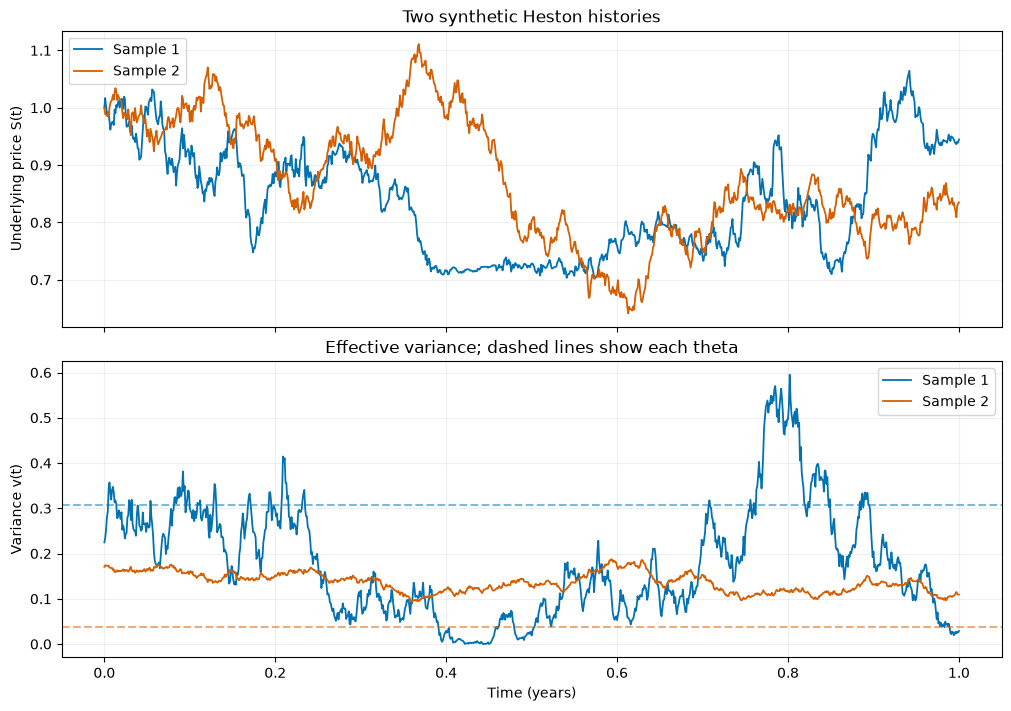

In [ ]:
fig, axes = plot_paths(sample)
plt.show()
plt.close(fig)


## 4. Histograms: one-step log returns

The logarithmic return is log(S[t+1]) - log(S[t]). Shared histogram bins make
the examples visually comparable. These are increments along a history, not
independent samples of the terminal-price distribution. Two paths are not
enough for conclusions about tails or market realism.


Return-array shape: (2, 1000)


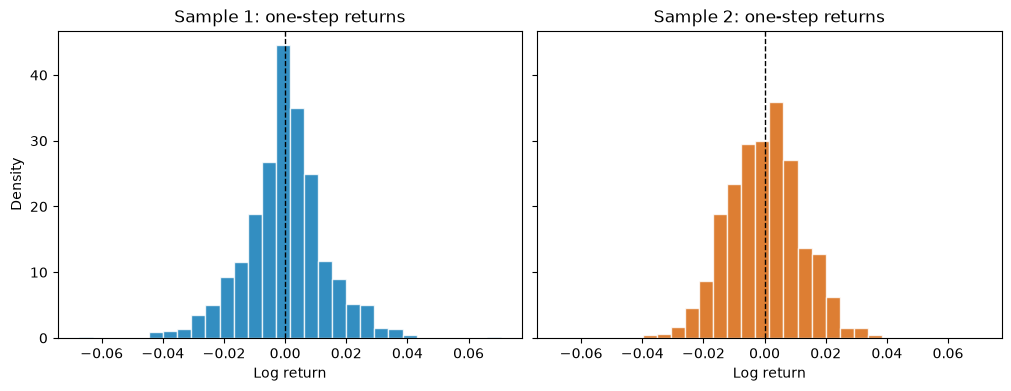

In [ ]:
returns = sample.log_returns()
print("Return-array shape:", returns.shape)
fig, axes = plot_return_histograms(sample, bins=30)
plt.show()
plt.close(fig)


## 5. Scatter plots: price and variance states

Colour indicates time. The scatter is a relationship between levels; its
correlation is not the shock correlation rho used in the Heston equations.


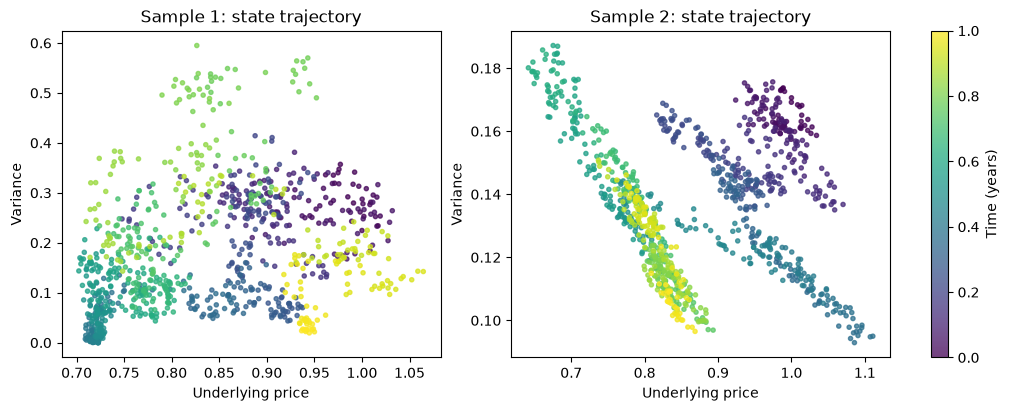

In [ ]:
fig, axes = plot_price_variance(sample)
plt.show()
plt.close(fig)


## 6. Drawdown and numerical summaries

Drawdown is 1 - S(t)/max(S up to t). A value of 0.10 means the sampled price is
10% below its previous peak. Mean variance is the average of stored grid values.
These quantities describe simulated histories; no trading strategy is tested.


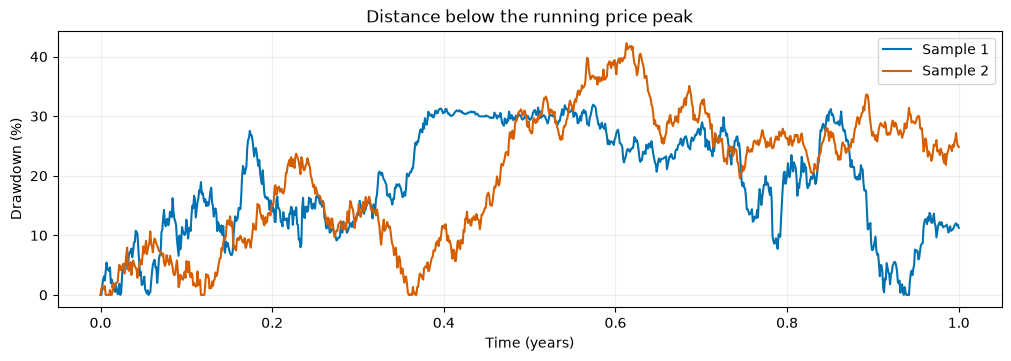

sample | terminal S | log return | mean variance | max drawdown
     1 |      0.94464 |     -0.05695 |      0.18048 |      0.31940
     2 |      0.83498 |     -0.18035 |      0.13665 |      0.42242


In [ ]:
fig, ax = plot_drawdowns(sample)
plt.show()
plt.close(fig)

print("sample | terminal S | log return | mean variance | max drawdown")

for i, row in enumerate(sample.summary(), start=1):
    print(f"{i:6d} | " + " | ".join(f"{value:12.5f}" for value in row))


## 7. Save and reload the dataset

Use pathlib for file locations and a compressed NumPy archive for arrays and
metadata. Run the notebook from either this demo directory or the project root.
The archive is numeric and does not require pickle. The terminal demo also
exports readable CSV versions into data/.


In [ ]:
cwd = Path.cwd()
project_root = next(
    (
        folder
        for folder in (cwd, *cwd.parents)
        if (folder / "heston_micro").is_dir()
        and (folder / "pyproject.toml").is_file()
    ),
    None,
)

if project_root is None:
    raise RuntimeError(
        "Launch the notebook from the project root or demo directory."
    )

archive = save_sample(sample, project_root / "data" / "two_heston_samples.npz")
reloaded = load_sample(archive)
np.testing.assert_array_equal(reloaded.prices, sample.prices)
np.testing.assert_array_equal(reloaded.variances, sample.variances)
print("Saved and verified:", archive.name)


Saved and verified: two_heston_samples.npz


## 8. Reproducibility and a simple limiting-case check

Resetting the seed once at the beginning reproduces the dataset. We never reset
it inside the time loop. In the zero-variance, zero-long-run-variance case, prices
follow the deterministic exponential S(t) = S(0) exp(drift*t).


In [ ]:
from heston_micro import generate_samples

repeat = generate_samples(
    2, maturities=maturities, steps_per_year=1000, seed=42
)
np.testing.assert_array_equal(repeat.parameters, sample.parameters)
np.testing.assert_array_equal(repeat.prices, sample.prices)

zero_variance_parameters = np.array([[0.0, 1.0, 0.0, 0.0, 0.0]])
check_prices, check_variances = simulate_heston_paths(
    zero_variance_parameters,
    times,
    np.random.default_rng(123),
    drift=0.03,
)
np.testing.assert_allclose(check_prices[0], np.exp(0.03 * times))
np.testing.assert_array_equal(check_variances, np.zeros_like(check_variances))
print(
    "Reproducibility, file round trip, and deterministic-limit checks passed."
)


Reproducibility, file round trip, and deterministic-limit checks passed.


## Interpretation and scope

- This demo produced **two different parameter draws**, each with a joint
  underlying-price and effective-variance history.
- Numerical paths are approximations, and coarse grids can distort results.
- The prior is chosen for this synthetic exercise; it is not fitted to market data.
- Neither the plots nor two samples establish statistical calibration or realism.
- A later option-price history requires a separate conditional pricing stage.

### Connection to lectures
LecNotesA: modular programming (2.1), files (2.3), exceptions (2.4), NumPy (3.1)
and Matplotlib's Figure/Axes interface (3.2). LecNotesB supplies the Git workflow
for reviewing and recording a reproducible submission. The stochastic model is
from the project draft; it is not presented as lecture content.

### Small exercises for understanding
1. Change the seed and explain what stays fixed and what changes.
2. Change `n_samples` to 5 and predict every array shape before running.
3. Explain why taking sqrt of raw negative Euler variance is invalid.
4. Explain why changing seed is not a controlled test of a single parameter.
